# Data Audit & Preliminary EDA: Weis & Dawid (2026)

**Appendix to Section 2.** *Optimizing bike-sharing station locations* (PLOS ONE, 2026) [1], study data from the authors' repository [2].

**Objective.** Check what the repository actually ships (row counts, dimensions, data types, missing values) against what the paper says, log every wrangling quirk met during ingestion, and explore the 15 inputs the models were trained on.

**Subset and sampling.** No sampling was needed. The largest table has 86,400 rows. Every table is inventoried, and the detailed checks focus on the **Warsaw grid** and the **4,341-row training table** built from it, because Warsaw is the only city whose station labels are in the repository.

## Summary

The repository holds 18 shapefile tables for three cities. The paper reports none of the basic counts, so I rebuilt them. The Warsaw grid has 86,400 cells of 100 m × 100 m with 130 attributes each. Its 350 bike stations fall into 341 cells, so only **0.39%** of cells contain a station. The models were not trained on this grid. They were trained on a smaller table holding all 341 station cells plus 4,000 of the 86,059 empty ones, which makes **7.9%** of its rows station cells. The paper describes the oversampling step that came next, but it never mentions this earlier cut.

Most of the missing values turn out not to be missing. Fifty of the 130 columns have blanks, in some cases in more than 99.9% of rows. A blank means "no such object in this cell", and it becomes 0 in the rescaled copy. The one real gap is population: 22 cells on the grid's outer edge have no value. Four of those cells reached the training table as 0, which the model reads as "nobody lives here". I found no −999-style codes and no empty strings.

Two quieter quirks change how the inputs should be read. Formula (1) in the paper rescales each attribute over "the entire dataset", but the training table was rescaled again on its own 4,341 rows, which moved some values by up to 0.58. Also, five of the 15 inputs are blends of five distance zones weighted 16:8:4:2:1, and the paper does not say so.

Zeros dominate the inputs (up to 96% of rows), and 14 of the 15 are strongly right-skewed. The extreme values come from real city-centre cells, not errors. Distance to the centre is the clearest single signal: the median station cell lies 3.9 km from the centre, against 11.9 km for cells without one.

## Setup

### Packages

In [1]:
%pip install --quiet --disable-pip-version-check pandas geopandas pyogrio matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


### Data

The dataset is not kept in the repository: it unpacks to 684 MB, and two of its tables are past GitHub's file-size limit. This cell fetches it once from the authors' figshare record (CC BY 4.0) and skips if it is already on disk.

In [2]:
from pathlib import Path
import urllib.request, zipfile

# shared_data.zip, 153 MB, from doi:10.6084/m9.figshare.31566433
data_files = Path("shared_data/study_data/files")

if data_files.exists():
    print("Dataset already present.")
else:
    print("Downloading the dataset, 153 MB...")
    urllib.request.urlretrieve("https://ndownloader.figshare.com/files/63097930", "shared_data.zip")
    zipfile.ZipFile("shared_data.zip").extractall(".")
    Path("shared_data.zip").unlink()

Dataset already present.


### Imports and configuration

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown, display

DATA = Path("shared_data/study_data/files")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
colours = sns.color_palette("colorblind")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)

In [ ]:
# Helper code: plain-English names for the 15 model inputs (my reading of the Polish abbreviations) S1, S8
INPUT_NAMES = {
    "w_au_tra": "Bus/tram stops",
    "w_trasy_r": "Cycle-route length",
    "w_drogi": "Road length",
    "w_gest1": "Population density",
    "w_d_centr": "Distance to centre",
    "w_kult": "Culture sites (blend)",
    "w_han_usl": "Shops & services (blend)",
    "w_szk": "Schools (blend)",
    "w_rel": "Religious sites (blend)",
    "w_h_u_100": "Shops & services, 100 m zone",
    "w_szk_200": "Schools, 200 m zone",
    "w_muz": "Museums (blend)",
    "w_kult_200": "Culture sites, 200 m zone",
    "w_muz_200": "Museums, 200 m zone",
    "w_muz_300": "Museums, 300 m zone",
}


def read_table(relative_path):
    # Only the attribute table is needed; skipping the polygons makes loading much faster
    return gpd.read_file(DATA / relative_path, ignore_geometry=True)

## Plan

1. **Verify the dataset.** Inventory every table, then check grid sizes, data types, labels and keys against the paper.
2. **Audit missing values and quirks.** Work out what blanks mean, look for sentinel codes, find the real gaps, and test how the training table was built.
3. **Univariate summary.** Mean, median, spread, share of zeros and skew for the 15 inputs, plus the station share at each stage.
4. **Outlier and skew audit.** Classify the skew and decide whether extreme values are errors or real signal.
5. **EDA figures.** Three plots: station share by stage, the shape of the inputs, and how the inputs correlate.
6. **Data card.** One-page record of the dataset as shipped.

The order of the checks — structure, completeness, distributions, then relationships — follows standard data-profiling practice [4].

## 1. Dataset verification

### 1.1 What is in the repository?

In [5]:
inventory_rows = []
for path in sorted(DATA.rglob("*.shp")):
    info = pyogrio.read_info(path)
    inventory_rows.append({
        "folder": path.parent.relative_to(DATA).as_posix(),
        "table": path.stem,
        "rows": info["features"],
        "attributes": len(info["fields"]),
        "CRS": info["crs"] or "missing",
    })

inventory = pd.DataFrame(inventory_rows)
inventory

,folder,table,rows,attributes,CRS
0,apply_area,rz_siatka100_dla_ann_python,30600,15,EPSG:2180
1,apply_area,rz_siatka100_python,30600,2,EPSG:2180
2,apply_area/tan1_ann_reg_rz,tanh1_rz,218,1,missing
3,test_area,ldz_siatka100_ann_wynik_python,42874,1,EPSG:2180
4,test_area,ldz_siatka100_dla_ann_python,42874,15,EPSG:2180
5,test_area,ldz_siatka100_ges_pkt_lin_pow_buf_all,42874,125,EPSG:2180
6,test_area,ldz_siatka100_python,42874,2,EPSG:2180
7,test_area,ldz_siatka100_python_reg,42874,2,EPSG:2180
8,test_area/tanh_ann_reg,tanh1,176,1,EPSG:2180
9,test_area/tanh_ann_reg,tanh1_points,176,2,EPSG:2180


There are 18 tables. Only four feed the models: the Warsaw grid and the training table in `training_area`, plus the Łódź and Rzeszów input grids (`*_dla_ann_*`, "for the ANN"). The rest are model outputs, where `wynik` means "result". Every table uses the Polish national grid EPSG:2180 except two regression-output files, which ship without a projection file and cannot be placed on a map without guessing.

### 1.2 Loading the four core tables

In [6]:
warsaw = read_table("training_area/siatka100_ges_pkt_lin_pow_row_buf.shp")
training = read_table("training_area/siatka100_python.shp")
lodz = read_table("test_area/ldz_siatka100_ges_pkt_lin_pow_buf_all.shp")
lodz_inputs = read_table("test_area/ldz_siatka100_dla_ann_python.shp")
rzeszow_inputs = read_table("apply_area/rz_siatka100_dla_ann_python.shp")

inputs = [column for column in training.columns if column.startswith("w_")]

print(f"Warsaw grid:      {warsaw.shape[0]:>6,} rows x {warsaw.shape[1]} columns")
print(f"Training table:   {training.shape[0]:>6,} rows x {training.shape[1]} columns ({len(inputs)} inputs + id + label)")
print(f"Łódź grid:        {lodz.shape[0]:>6,} rows x {lodz.shape[1]} columns")
print(f"Rzeszów inputs:   {rzeszow_inputs.shape[0]:>6,} rows x {rzeszow_inputs.shape[1]} columns")

Warsaw grid:      86,400 rows x 130 columns
Training table:    4,341 rows x 17 columns (15 inputs + id + label)
Łódź grid:        42,874 rows x 125 columns
Rzeszów inputs:   30,600 rows x 15 columns


### 1.3 Do the grid sizes match the paper?

The paper gives the city areas (517.2 km² for Warsaw, 293.3 km² for Łódź) and the cell size, but not the number of cells.

In [7]:
cell_width = (warsaw["right"] - warsaw["left"]).unique()
cell_height = (warsaw["top"] - warsaw["bottom"]).unique()
print("Cell size in metres:", cell_width, "x", cell_height)

grid_check = pd.DataFrame({
    "cells": [len(warsaw), len(lodz)],
    "columns": [warsaw["left"].nunique(), lodz["left"].nunique()],
    "rows": [warsaw["top"].nunique(), lodz["top"].nunique()],
    "city area in paper (km²)": [517.2, 293.3],
}, index=["Warsaw", "Łódź"])

grid_check["grid area (km²)"] = grid_check["cells"] / 100  # one cell = 1 ha = 0.01 km²
grid_check["grid beyond city (%)"] = 100 * (1 - grid_check["city area in paper (km²)"] / grid_check["grid area (km²)"])
grid_check.round(1)

Cell size in metres: [100.] x [100.]


,cells,columns,rows,city area in paper (km²),grid area (km²),grid beyond city (%)
Warsaw,86400,288,300,517.2,864.0,40.1
Łódź,42874,221,194,293.3,428.7,31.6


The cell size checks out at exactly 100 m. Both grids are full rectangles (columns × rows = cells), so they reach past the city limits. Warsaw's grid covers 864 km² against a city area of 517 km², so roughly two fifths of the grid area falls outside the boundary. This is an area-to-area comparison, not a cell-by-cell one: the repository ships no city-boundary layer, so I cannot label individual cells as inside or outside. Whatever does fall outside can only add "no station" cells, and the paper never mentions that the grid runs past the city.

### 1.4 Data types, first and last rows

In [8]:
print("Warsaw grid column types:   ", warsaw.dtypes.astype(str).value_counts().to_dict())
print("Training table column types:", training.dtypes.astype(str).value_counts().to_dict())
print("Cell id is stored as", warsaw["id"].dtype, "in the grid and", training["id"].dtype, "in the training table")

pd.concat([training.head(3), training.tail(3)])

Warsaw grid column types:    {'float64': 127, 'int64': 3}
Training table column types: {'float64': 15, 'int64': 2}
Cell id is stored as float64 in the grid and int64 in the training table


,id,w_au_tra,w_trasy_r,w_drogi,w_gest1,w_d_centr,w_kult,w_han_usl,w_szk,w_rel,w_h_u_100,w_szk_200,w_muz,w_kult_200,w_muz_200,w_muz_300,target
0,39,0.0,0.0,0.0,0.000,0.657,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,42,0.0,0.0,0.0,0.000,0.647,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,44,0.0,0.0,0.0,0.000,0.641,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4338,86338,0.0,0.0,0.0,0.000,0.866,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4339,86372,0.0,0.0,0.0,0.002,0.937,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4340,86397,0.0,0.0,0.0,0.121,1.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


Every column is numeric. The only surprise is that the cell `id` is a decimal number in the grid but an integer in the training table, so joining the two tables needs an explicit type conversion. The first and last rows show that the training table is sorted by cell id, so station and empty cells are interleaved rather than grouped.

### 1.5 How many stations, and how is the label stored?

In [9]:
stations_per_cell = warsaw["st_row"].value_counts().sort_index().rename(index=int).astype(int)
print("Total stations:", int(warsaw["st_row"].sum()))
print("Cells by number of stations:", stations_per_cell.to_dict())
print("Binary label w_st_r_01:", warsaw["w_st_r_01"].value_counts().to_dict())
print("Training table label:", training["target"].value_counts().to_dict())
print("Label columns in the Łódź grid:", [c for c in lodz.columns if c.startswith(("st_", "w_st"))])

Total stations: 350
Cells by number of stations: {0: 86059, 1: 333, 2: 7, 3: 1}
Binary label w_st_r_01: {0: 86059, 1: 341}
Training table label: {0: 4000, 1: 341}
Label columns in the Łódź grid: []


Warsaw has 350 stations in 341 cells. The eight cells that hold two or three stations count as a single "yes", which is reasonable for a "should a station go here?" question. The label appears three times: as a count (`st_row`), as a rescaled count (`w_st_rower`) and as a 0/1 flag (`w_st_r_01`). The Łódź grid has **no label column**, so the paper's Łódź validation cannot be checked from the repository.

### 1.6 Are the cell ids a clean key?

In [10]:
missing_ids = sorted(set(range(1, len(warsaw) + 1)) - set(warsaw["id"].astype(int)))
print("ids missing from 1 to 86,400:", missing_ids)
warsaw[warsaw["id"].duplicated(keep=False)][["id", "left", "top"]]

ids missing from 1 to 86,400: [1]


,id,left,top
0,29809.0,626505.916,502172.428
29808,29809.0,636405.916,491372.428


Cell 29809 appears twice and cell 1 is missing. The first copy (row 0) sits at the grid's top-left corner, and the cell directly below it is id 2, so row 0 must be cell 1. I correct it before any join. Otherwise a lookup by id would quietly return the wrong cell.

In [11]:
warsaw.loc[0, "id"] = 1
warsaw["id"] = warsaw["id"].astype(int)
warsaw_by_id = warsaw.set_index("id")

grid_labels = warsaw_by_id.loc[training["id"], "w_st_r_01"].to_numpy()
print("ids now unique:", warsaw["id"].is_unique)
print("Every training id found in the grid:", training["id"].isin(warsaw["id"]).all())
print("Training labels agree with grid labels:", (grid_labels == training["target"].to_numpy()).all())

ids now unique: True
Every training id found in the grid: True
Training labels agree with grid labels: True


## 2. Missing values and wrangling quirks

### 2.1 How much is blank?

In [12]:
blank_share = warsaw.isna().mean() * 100
blank_share = blank_share[blank_share > 0].sort_values()

print(f"{len(blank_share)} of {warsaw.shape[1]} columns contain blanks")
bands = pd.cut(blank_share, bins=[0, 1, 75, 95, 100], labels=["under 1%", "1-75%", "75-95%", "over 95%"])
print("Columns by share of blank rows:", bands.value_counts().sort_index().to_dict())

blank_share.round(2).iloc[[0, 1, 2, -3, -2, -1]].to_frame("% blank")

50 of 130 columns contain blanks
Columns by share of blank rows: {'under 1%': 2, '1-75%': 2, '75-95%': 19, 'over 95%': 27}


,% blank
gest1,0.03
w_gest1,0.03
bud_area_2,64.46
zab100_are,99.87
wysyp_area,99.93
zabyt_area,99.98


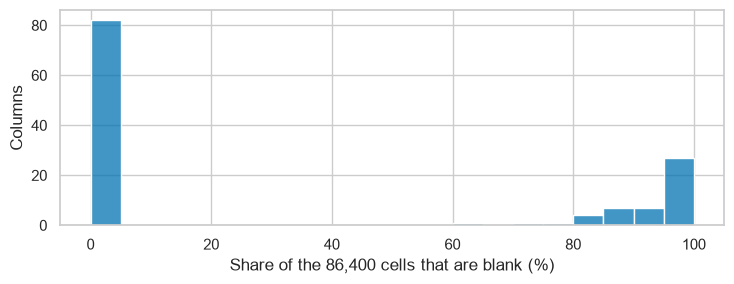

In [13]:
all_blank_share = warsaw.isna().mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 3.0))
sns.histplot(all_blank_share, bins=np.arange(0, 105, 5), color=colours[0], ax=ax)
ax.set_xlabel("Share of the 86,400 cells that are blank (%)")
ax.set_ylabel("Columns")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_missingness.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 1.** How blankness is spread across the 130 Warsaw columns, in 5-point bins. The distribution is split rather than gradual: 82 columns are complete or nearly so (80 of them have no blanks at all) and 34 are more than 90% blank, with almost nothing between. That shape is the first clue that a blank records an absent object rather than a lost measurement.

### 2.2 Does a blank mean "unknown" or "nothing here"?

If blanks were unknown values, real zeros would be common. If a blank means "no such object in this cell", then zeros should be rare in the raw columns, and the rescaled copies should hold 0 wherever the raw value is blank.

In [14]:
area_columns = [column for column in blank_share.index if column not in ("gest1", "w_gest1")]
literal_zeros = int((warsaw[area_columns] == 0).sum().sum())
print(f"Literal zeros across the {len(area_columns)} blank-containing area columns: {literal_zeros}")

# Rebuild each rescaled zone input from its raw column: fill blanks with 0, then min-max over the whole grid
raw_to_rescaled = {
    "h_u_100_ar": "w_h_u_100",
    "szk200_are": "w_szk_200",
    "kult200_ar": "w_kult_200",
    "muz200_are": "w_muz_200",
    "muz300_are": "w_muz_300",
}
rebuild_rows = []
for raw, rescaled in raw_to_rescaled.items():
    is_blank = warsaw[raw].isna()
    filled = warsaw[raw].fillna(0)
    rebuilt = (filled - filled.min()) / (filled.max() - filled.min())
    rebuild_rows.append({
        "raw column": raw,
        "rescaled column": rescaled,
        "blank cells": int(is_blank.sum()),
        "rescaled values at blanks": warsaw.loc[is_blank, rescaled].unique().tolist(),
        "largest mismatch after rebuild": (rebuilt - warsaw[rescaled]).abs().max(),
    })
pd.DataFrame(rebuild_rows)

Literal zeros across the 48 blank-containing area columns: 10


,raw column,rescaled column,blank cells,rescaled values at blanks,largest mismatch after rebuild
0,h_u_100_ar,w_h_u_100,69173,[0.0],4.999e-04
1,szk200_are,w_szk_200,71168,[0.0],5.000e-04
2,kult200_ar,w_kult_200,82678,[0.0],4.999e-04
3,muz200_are,w_muz_200,84039,[0.0],5.000e-04
4,muz300_are,w_muz_300,83250,[0.0],4.999e-04


The area columns contain only a handful of literal zeros, and every blank becomes exactly 0 in the rescaled copy. A blank therefore means "none here". The rebuild matches to within 0.0005, which is half of the last decimal place kept, so the rescaled values were also **rounded to three decimals**. That rounding is not mentioned in the paper either.

### 2.3 Are there special missing-value codes?

In [15]:
core_tables = {
    "Warsaw grid": warsaw,
    "Training table": training,
    "Łódź grid": lodz,
    "Rzeszów inputs": rzeszow_inputs,
}
sentinel_codes = [-9999, -999, -99, 9999]

sentinel_rows = []
for name, table in core_tables.items():
    values = table.select_dtypes("number").drop(columns="id", errors="ignore")  # id 9999 is a real cell
    sentinel_rows.append({
        "table": name,
        "sentinel codes": int(values.isin(sentinel_codes).sum().sum()),
        "negative values": int((values < 0).sum().sum()),
        "text columns": table.select_dtypes(exclude="number").shape[1],
        "blank cells": int(table.isna().sum().sum()),
    })
pd.DataFrame(sentinel_rows)

,table,sentinel codes,negative values,text columns,blank cells
0,Warsaw grid,0,0,0,3855989
1,Training table,0,0,0,0
2,Łódź grid,0,0,0,1921832
3,Rzeszów inputs,0,0,0,0


None of the tables use codes such as −999, negative values or text fields. Blanks in the raw grids are the only form of missingness. The model-ready tables have none, because the blanks were already turned into zeros.

### 2.4 Where are the genuine gaps?

Population density is the one input where a blank cannot mean "nothing here", because every cell has some population value.

In [16]:
no_population = warsaw["gest1"].isna()
on_outer_edge = (
    warsaw["left"].isin([warsaw["left"].min(), warsaw["left"].max()])
    | warsaw["top"].isin([warsaw["top"].min(), warsaw["top"].max()])
)
print(f"Cells with no population value: {no_population.sum()}, of which on the grid's outer edge: {(no_population & on_outer_edge).sum()}")

population_gap_ids = warsaw.loc[no_population, "id"]
gaps_in_training = training[training["id"].isin(population_gap_ids)][["id", "w_gest1", "target"]]
gaps_in_training

Cells with no population value: 22, of which on the grid's outer edge: 22


,id,w_gest1,target
1833,35701,0.0,0
2468,47101,0.0,0
2833,54300,0.0,0
3556,69001,0.0,0


All 22 gaps sit on the outer edge of the grid, where the population raster presumably stops short of the grid. Four of these cells made it into the training table with population 0. They are empty cells either way, so the effect is small, but the model is told "nobody lives here" when the honest value is "unknown".

### 2.5 Was the training table rescaled the way the paper says?

Formula (1) takes the minimum and maximum "for the entire dataset". If that is what happened, the training rows would keep the values they have in the full grid.

In [17]:
training_values = training.set_index("id")[inputs]
grid_values = warsaw_by_id.loc[training["id"], inputs]

rescale_check = pd.DataFrame({
    "min in training table": training_values.min(),
    "max in training table": training_values.max(),
    "max of same cells in grid": grid_values.max(),
    "largest shift": (training_values - grid_values.to_numpy()).abs().max(),
})
rescale_check.index = rescale_check.index.map(INPUT_NAMES)

for name, table in [("Łódź", lodz_inputs), ("Rzeszów", rzeszow_inputs)]:
    print(f"{name}: inputs whose maximum is exactly 1: {int((table[inputs].max() == 1).sum())} of {len(inputs)}")

rescale_check.sort_values("largest shift", ascending=False).round(3)

Łódź: inputs whose maximum is exactly 1: 15 of 15
Rzeszów: inputs whose maximum is exactly 1: 15 of 15


,min in training table,max in training table,max of same cells in grid,largest shift
Bus/tram stops,0.0,1.0,0.417,0.583
Culture sites (blend),0.0,1.0,0.516,0.484
Shops & services (blend),0.0,1.0,0.516,0.484
Schools (blend),0.0,1.0,0.516,0.484
Religious sites (blend),0.0,1.0,0.645,0.355
Cycle-route length,0.0,1.0,0.748,0.252
Museums (blend),0.0,1.0,0.774,0.226
Road length,0.0,1.0,0.840,0.160
Population density,0.0,1.0,0.861,0.139
"Museums, 300 m zone",0.0,1.0,0.974,0.026


They do not. In the training table every input runs exactly from 0 to 1, even where the same cells peak well below 1 in the grid, so the 4,341 rows were **rescaled again on their own**. Some values moved by more than half the scale. The Łódź and Rzeszów tables are each scaled against themselves as well. A value of 1 therefore means "the highest in this particular table", not one fixed physical amount.

### 2.6 What are the inputs without a direct raw column?

Five inputs (the "blend" ones) do not match a min–max rescaling of any single raw column. I tested whether each one combines its own 100–500 m zones with weights that halve at each step.

In [ ]:
zone_weights = np.array([16, 8, 4, 2, 1])  # halving by distance zone
zone_weights = zone_weights / zone_weights.sum()
blends = {
    "w_han_usl": "w_h_u_",
    "w_kult": "w_kult_",
    "w_szk": "w_szk_",
    "w_rel": "w_rel_",
    "w_muz": "w_muz_",
}
blend_rows = []
for blend, prefix in blends.items():
    zones = warsaw[[f"{prefix}{distance}" for distance in (100, 200, 300, 400, 500)]].fillna(0)
    rebuilt = zones.to_numpy() @ zone_weights
    blend_rows.append({"input": INPUT_NAMES[blend], "largest gap after rebuild": np.abs(rebuilt - warsaw[blend]).max()})

blend_check = pd.DataFrame(blend_rows)
blend_check.round(4)

,input,largest gap after rebuild
0,Shops & services (blend),7.000e-04
1,Culture sites (blend),7.000e-04
2,Schools (blend),7.000e-04
3,Religious sites (blend),7.000e-04
4,Museums (blend),7.000e-04


All five rebuild exactly, apart from the three-decimal rounding. Each is a distance-weighted mix: 16/31 of the 100 m zone, 8/31 of the 200 m zone, and so on down to 1/31 of the 500 m zone. This is a sensible design, but the paper does not describe it, so a reader cannot rebuild a third of the inputs from the paper alone.

### 2.7 How were the 4,000 empty cells chosen, and are they representative?

In [19]:
empty_in_grid = int((warsaw["w_st_r_01"] == 0).sum())
empty_in_training = int((training["target"] == 0).sum())
print(f"Empty cells kept for training: {empty_in_training:,} of {empty_in_grid:,} ({empty_in_training / empty_in_grid:.1%})")

sampled_empty = warsaw[warsaw["id"].isin(training.loc[training["target"] == 0, "id"])]
all_empty = warsaw[warsaw["w_st_r_01"] == 0]

sample_rows = []
for column, label in [("d_centr", "Distance to centre (m)"), ("gest1", "Population per cell"), ("d_drogi", "Road length (m)")]:
    ks = stats.ks_2samp(sampled_empty[column].dropna(), all_empty[column].dropna())
    sample_rows.append({
        "variable": label,
        "median, sampled cells": sampled_empty[column].median(),
        "median, all empty cells": all_empty[column].median(),
        "p-value (two-sample KS test)": ks.pvalue,
    })
pd.DataFrame(sample_rows).round(3)

Empty cells kept for training: 4,000 of 86,059 (4.6%)


,variable,"median, sampled cells","median, all empty cells",p-value (two-sample KS test)
0,Distance to centre (m),11927.004,11897.143,0.635
1,Population per cell,3.362,4.090,0.018
2,Road length (m),0.000,0.000,0.412


Only 4.6% of the empty cells were kept. The paper describes oversampling the station cells but never this earlier undersampling of empty ones. Distance to the centre and road length match the full set closely, and population is slightly lower in the sample.

Two cautions on those p-values. Road length is more than half exact zeros and population about a third, while the test assumes continuous data, so those p-values are approximate. And across three tests, p ≈ 0.02 sits right at the edge of what a Bonferroni correction would keep. I read this as a sample close to random with a slight tilt towards emptier cells, not as proof either way.

### 2.8 Smaller formatting surprises

In [20]:
name_lengths = pd.Series(warsaw.columns).str.len()
print("Longest column name:", name_lengths.max(), "characters (the shapefile limit is 10)")
print("Only in the Warsaw grid:", sorted(set(warsaw.columns) - set(lodz.columns)))
print("Only in the Łódź grid:  ", sorted(set(lodz.columns) - set(warsaw.columns)))

repeated_rows = training.duplicated(subset=inputs)
groups = training[training.duplicated(subset=inputs, keep=False)].groupby(inputs)["target"].nunique()
print(f"Training rows repeating another row's 15 inputs: {repeated_rows.sum()} ({repeated_rows.mean():.1%}); groups with conflicting labels: {int((groups > 1).sum())}")

Longest column name: 10 characters (the shapefile limit is 10)
Only in the Warsaw grid: ['pkt_metro', 'st_row', 'w_metro', 'w_st_r_01', 'w_st_rower']
Only in the Łódź grid:   []
Training rows repeating another row's 15 inputs: 544 (12.5%); groups with conflicting labels: 0


Column names are Polish abbreviations cut to the 10-character shapefile limit (`kult_area_`, `muz100_are`), so a name dictionary is needed before analysis. The Warsaw grid has metro and label columns that Łódź lacks, and the authors ship a separate "bezmetra" (no-metro) Warsaw file for that reason. About one training row in eight repeats another row's inputs exactly. None of these repeats conflict on the label, but they matter once rows are copied by oversampling.

### 2.9 Quirk log

In [21]:
quirk_log = f'''
| # | Quirk | Evidence | Why it matters |
|---|---|---|---|
| 1 | A blank means "none here", not "unknown" | {len(area_columns)} area columns, up to {blank_share.max():.2f}% blank; {literal_zeros} literal zeros; every blank becomes 0 when rescaled | Safe to read as 0, but the convention is undocumented |
| 2 | Real gaps in population | {int(no_population.sum())} edge cells blank; {len(gaps_in_training)} reached training as 0 | "Unknown" is fed to the model as "nobody lives here" |
| 3 | Training table rescaled on itself | every input spans 0–1 in {len(training):,} rows; shifts up to {rescale_check["largest shift"].max():.2f} | Contradicts formula (1); "1" means something different in each table |
| 4 | Five undisclosed blended inputs | 16:8:4:2:1 zone weights rebuild them to within {blend_check["largest gap after rebuild"].max():.4f} | A third of the inputs cannot be reproduced from the paper |
| 5 | Undisclosed cut of empty cells | {empty_in_training:,} of {empty_in_grid:,} kept | Station share rises from {warsaw["w_st_r_01"].mean():.2%} to {training["target"].mean():.1%} before oversampling |
| 6 | Duplicate cell id | id 29809 twice, id 1 missing; fixed by grid position | A join on id silently returns the wrong cell |
| 7 | Repeated input rows | {int(repeated_rows.sum())} rows ({repeated_rows.mean():.1%}) repeat another row | Interacts with oversampling (Section 3) |
| 8 | Format | Polish names cut to 10 characters; values rounded to 3 decimals; id stored as a decimal; 2 files without CRS | Ingestion needs a name dictionary and explicit types |
'''
display(Markdown(quirk_log))


| # | Quirk | Evidence | Why it matters |
|---|---|---|---|
| 1 | A blank means "none here", not "unknown" | 48 area columns, up to 99.98% blank; 10 literal zeros; every blank becomes 0 when rescaled | Safe to read as 0, but the convention is undocumented |
| 2 | Real gaps in population | 22 edge cells blank; 4 reached training as 0 | "Unknown" is fed to the model as "nobody lives here" |
| 3 | Training table rescaled on itself | every input spans 0–1 in 4,341 rows; shifts up to 0.58 | Contradicts formula (1); "1" means something different in each table |
| 4 | Five undisclosed blended inputs | 16:8:4:2:1 zone weights rebuild them to within 0.0007 | A third of the inputs cannot be reproduced from the paper |
| 5 | Undisclosed cut of empty cells | 4,000 of 86,059 kept | Station share rises from 0.39% to 7.9% before oversampling |
| 6 | Duplicate cell id | id 29809 twice, id 1 missing; fixed by grid position | A join on id silently returns the wrong cell |
| 7 | Repeated input rows | 544 rows (12.5%) repeat another row | Interacts with oversampling (Section 3) |
| 8 | Format | Polish names cut to 10 characters; values rounded to 3 decimals; id stored as a decimal; 2 files without CRS | Ingestion needs a name dictionary and explicit types |


## 3. Univariate summary

### 3.1 How rare is a station cell at each stage?

In [22]:
base_rates = pd.Series({
    "Whole Warsaw grid": warsaw["w_st_r_01"].mean(),
    "Training table": training["target"].mean(),
    "After oversampling (as the paper describes)": 0.5,
}, name="share of station cells")

print(f"The training table has {base_rates.iloc[1] / base_rates.iloc[0]:.0f} times the real share of station cells")
base_rates.map("{:.2%}".format).to_frame()

The training table has 20 times the real share of station cells


,share of station cells
Whole Warsaw grid,0.39%
Training table,7.86%
After oversampling (as the paper describes),50.00%


In the real city, about one cell in 250 has a station. The models first see one in 13, and after oversampling one in 2. Any accuracy figure therefore describes performance in a balanced world, not in the city where the predictions will be used.

### 3.2 Summary statistics for the 15 inputs (training table)

In [23]:
X = training[inputs]
z_scores = (X - X.mean()) / X.std()

univariate = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "std": X.std(),
    "variance": X.var(),
    "% zero": (X == 0).mean() * 100,
    "median when non-zero": X[X > 0].median(),
    "skew": X.skew(),
    "cells beyond 3 SD": (z_scores.abs() > 3).sum(),
})
univariate.index = univariate.index.map(INPUT_NAMES)
univariate = univariate.sort_values("skew", ascending=False)
univariate.round(3)

,mean,median,std,variance,% zero,median when non-zero,skew,cells beyond 3 SD
Museums (blend),0.020,0.000,0.093,0.009,88.643,0.087,7.045,80
"Museums, 200 m zone",0.023,0.000,0.136,0.019,96.061,0.629,6.309,105
"Museums, 300 m zone",0.022,0.000,0.122,0.015,95.139,0.432,6.129,113
"Culture sites, 200 m zone",0.023,0.000,0.121,0.015,94.794,0.433,5.856,121
Bus/tram stops,0.021,0.000,0.086,0.007,92.421,0.199,5.250,94
Religious sites (blend),0.037,0.000,0.115,0.013,77.655,0.113,5.006,68
Culture sites (blend),0.038,0.000,0.134,0.018,83.391,0.124,4.782,126
Cycle-route length,0.024,0.000,0.097,0.010,92.099,0.297,4.681,133
"Schools, 200 m zone",0.082,0.000,0.214,0.046,79.360,0.341,2.757,185
"Shops & services, 100 m zone",0.097,0.000,0.244,0.059,76.733,0.338,2.657,204


For 14 of the 15 inputs the median is lower than the mean, which is the sign of a long right tail. For most inputs the median itself is 0. Even among cells that do have the feature, values can sit very low on the 0–1 scale. The median populated cell scores just 0.055 for population density, because a few very dense blocks set the maximum. Distance to the centre is the only input that is close to symmetric.

### 3.3 Station cells versus empty cells, in real units (whole grid)

In [24]:
contrast = warsaw.groupby("w_st_r_01")[["d_centr", "gest1", "d_drogi", "pkt_au_tra"]].median()
contrast["d_centr"] = contrast["d_centr"] / 1000
contrast.index = ["No station", "Station"]
contrast.columns = ["Distance to centre (km)", "Population per cell", "Road length in cell (m)", "Bus/tram stops"]
contrast.round(1)

,Distance to centre (km),Population per cell,Road length in cell (m),Bus/tram stops
No station,11.9,4.1,0.0,0.0
Station,3.9,89.7,259.6,1.0


The median station cell is 3.9 km from the centre, compared with 11.9 km for empty cells. It also holds about twenty times as many residents and about 260 m of road, while the median empty cell has no road at all.

## 4. Outlier and skew audit

### 4.1 How skewed are the inputs?

In [25]:
skew_band = pd.cut(
    univariate["skew"].abs(),
    bins=[0, 0.5, 1, 2, np.inf],
    labels=["roughly symmetric (<0.5)", "moderate (0.5-1)", "high (1-2)", "extreme (>2)"],
)
skew_band.value_counts().sort_index().to_frame("inputs")

,inputs
skew,
roughly symmetric (<0.5),1
moderate (0.5-1),0
high (1-2),2
extreme (>2),12


### 4.2 Are the extreme values errors or real places?

In [26]:
# Measured on the whole grid: a rate taken from the training table would inherit its inflated station share
grid_inputs = warsaw_by_id[inputs]
grid_z_scores = (grid_inputs - grid_inputs.mean()) / grid_inputs.std()
has_extreme_value = (grid_z_scores.abs() > 3).any(axis=1)

outlier_check = pd.DataFrame({
    "cells": [int(has_extreme_value.sum()), int((~has_extreme_value).sum())],
    "median distance to centre (km)": [
        warsaw_by_id.loc[has_extreme_value, "d_centr"].median() / 1000,
        warsaw_by_id.loc[~has_extreme_value, "d_centr"].median() / 1000,
    ],
    "station cells (%)": [
        warsaw_by_id.loc[has_extreme_value, "w_st_r_01"].mean() * 100,
        warsaw_by_id.loc[~has_extreme_value, "w_st_r_01"].mean() * 100,
    ],
}, index=["at least one input beyond 3 SD", "no extreme input"])
outlier_check.round(3)

,cells,median distance to centre (km),station cells (%)
at least one input beyond 3 SD,17706,6.785,1.796
no extreme input,68694,13.061,0.033


Fourteen inputs are highly or extremely skewed, with between 45 and about 200 training cells per input beyond three standard deviations (last column of the table in 3.2). To ask whether those extremes are errors I go back to the whole grid, because a rate read off the training table would inherit the inflated station share noted in 3.1. These are not data errors. Across the city a cell with at least one extreme input sits about half as far from the centre, and it is roughly 50 times more likely to hold a station. Removing them would delete the signal the models need. The real problem lies in the scaling: with min–max, a few extreme cells set the maximum and squeeze everyone else towards 0. A log or rank transform would keep the low end readable.

## 5. Exploratory figures

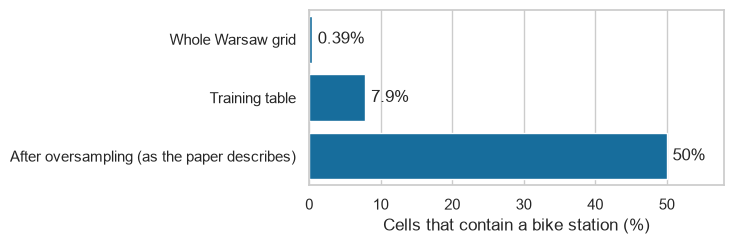

In [27]:
fig, ax = plt.subplots(figsize=(7.5, 2.6))
sns.barplot(x=base_rates.to_numpy() * 100, y=base_rates.index, color=colours[0], ax=ax)
for row, value in enumerate(base_rates.to_numpy() * 100):
    ax.text(value + 0.8, row, f"{value:.2g}%", va="center")
ax.set_xlim(0, 58)
ax.set_xlabel("Cells that contain a bike station (%)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES / "fig2_class_balance.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 2.** Share of cells that hold a bike station at each stage of the pipeline. The first two bars count real cells, the third includes duplicates. Two resampling steps take the share from 0.39% in the real city to 50%, and the paper reports only the second.

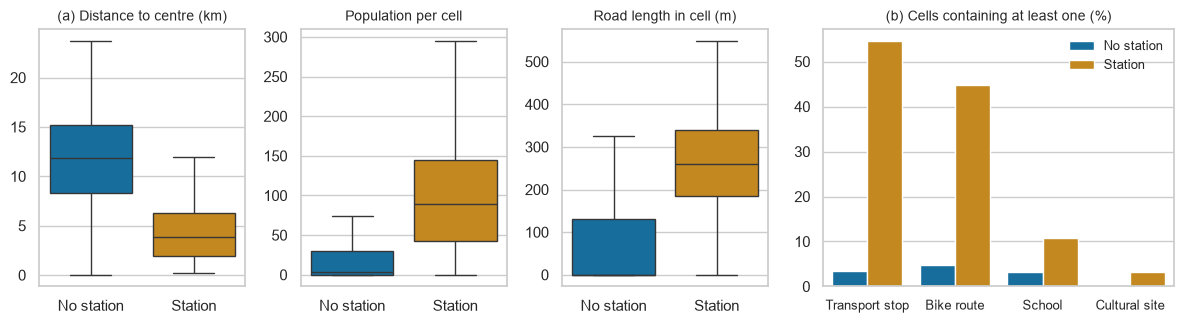

In [28]:
group = np.where(warsaw["w_st_r_01"] == 1, "Station", "No station")
order = ["No station", "Station"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 1, 1, 1.7]})

continuous = [
    ("(a) Distance to centre (km)", warsaw["d_centr"] / 1000),
    ("Population per cell", warsaw["gest1"]),
    ("Road length in cell (m)", warsaw["d_drogi"]),
]
for ax, (title, values) in zip(axes, continuous):
    sns.boxplot(x=group, y=values, order=order, hue=group, hue_order=order, palette="colorblind", legend=False, showfliers=False, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

presence_columns = {
    "Transport stop": "pkt_au_tra",
    "Bike route": "d_trasy_r",
    "School": "szk_area_2",
    "Cultural site": "kult_area_",
}
presence_rows = []
for label, column in presence_columns.items():
    has_feature = warsaw[column].fillna(0) > 0
    for name in order:
        presence_rows.append({"feature": label, "cells": name, "percent": has_feature[group == name].mean() * 100})
presence = pd.DataFrame(presence_rows)

sns.barplot(data=presence, x="feature", y="percent", hue="cells", hue_order=order, palette="colorblind", ax=axes[3])
axes[3].set_title("(b) Cells containing at least one (%)", fontsize=10)
axes[3].set_xlabel("")
axes[3].set_ylabel("")
axes[3].tick_params(axis="x", labelsize=9)
axes[3].legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURES / "fig3_station_vs_other.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 3.** What separates the 341 station cells from the rest of the Warsaw grid. (a) Three continuous inputs, outliers hidden. (b) Share of cells holding at least one of each feature. Station cells are closer in, denser and far more likely to contain a transport stop. Bike routes separate the two groups almost as sharply (44.9% against 4.8%), which sits oddly against the paper's finding that bike paths do not rank among the top factors.

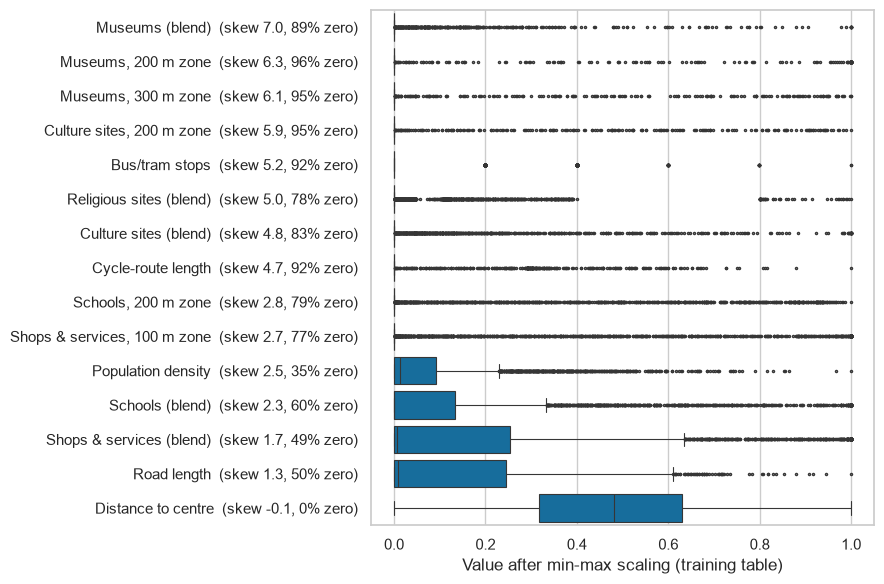

In [29]:
long_inputs = X.rename(columns=INPUT_NAMES).melt(var_name="input", value_name="scaled value")
order = list(univariate.index)
tick_labels = [f"{name}  (skew {univariate.loc[name, 'skew']:.1f}, {univariate.loc[name, '% zero']:.0f}% zero)" for name in order]

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=long_inputs, x="scaled value", y="input", order=order, color=colours[0], fliersize=1.5, linewidth=0.8, ax=ax)
ax.set_yticks(range(len(order)), labels=tick_labels)
ax.set_xlabel("Value after min-max scaling (training table)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES / "fig4_input_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 4.** Distribution of the 15 model inputs, sorted by skew. For most inputs the box has collapsed onto 0, so every cell that has the feature at all is drawn as an outlier. Distance to the centre (bottom) is the only input with a spread-out, symmetric shape.

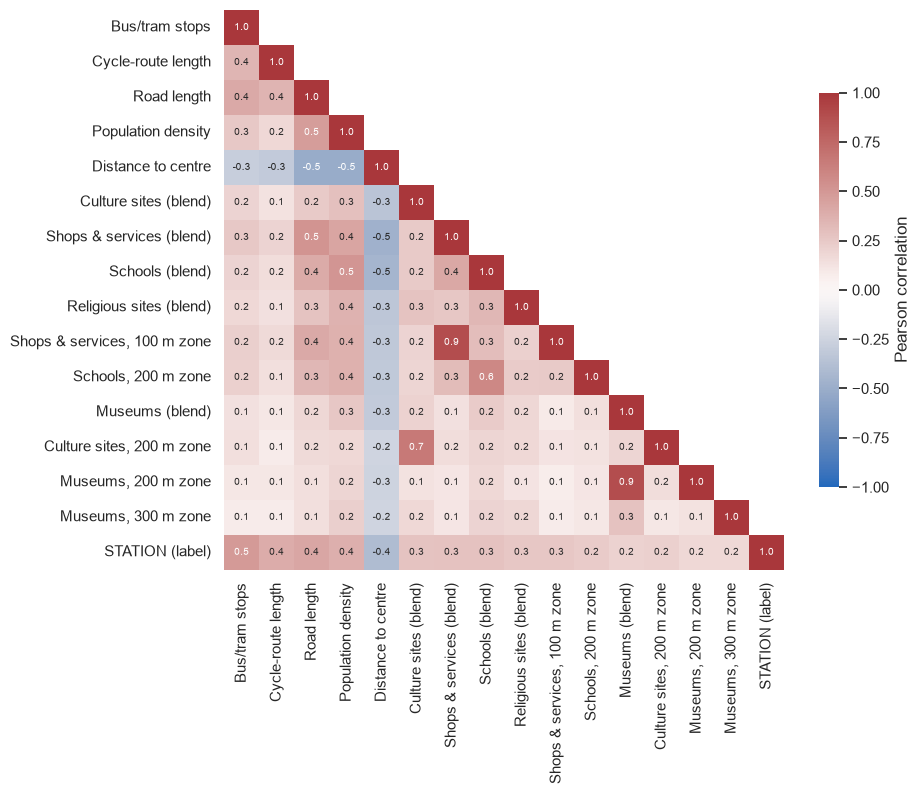

In [30]:
correlation_data = training[inputs + ["target"]].rename(columns={**INPUT_NAMES, "target": "STATION (label)"})
correlation = correlation_data.corr(method="pearson")
upper_triangle = np.triu(np.ones_like(correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(correlation, mask=upper_triangle, cmap="vlag", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".1f", annot_kws={"size": 7}, square=True,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES / "fig5_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 5.** Pearson correlations between the 15 inputs and the station label (bottom row), training table. Bus/tram stops, road length and cycle routes have the strongest positive links to a station, and distance to the centre has the strongest negative one. The two darkest off-diagonal cells pair a blend with its own 100 m or 200 m zone, so these pairs are redundant by construction.

In [31]:
label_correlation = pd.DataFrame({
    "Pearson": training[inputs].corrwith(training["target"]),
    "Spearman": training[inputs].corrwith(training["target"], method="spearman"),
})
label_correlation.index = label_correlation.index.map(INPUT_NAMES)
label_correlation["rank by Pearson"] = label_correlation["Pearson"].abs().rank(ascending=False).astype(int)
label_correlation["rank by Spearman"] = label_correlation["Spearman"].abs().rank(ascending=False).astype(int)

strong_pairs = [
    (INPUT_NAMES[a], INPUT_NAMES[b], round(training[a].corr(training[b]), 2))
    for i, a in enumerate(inputs) for b in inputs[i + 1:]
    if abs(training[a].corr(training[b])) >= 0.8
]
print("Input pairs with |r| >= 0.8:", strong_pairs)
label_correlation.sort_values("rank by Pearson").round(2)

Input pairs with |r| >= 0.8: [('Shops & services (blend)', 'Shops & services, 100 m zone', np.float64(0.89)), ('Museums (blend)', 'Museums, 200 m zone', np.float64(0.89))]


,Pearson,Spearman,rank by Pearson,rank by Spearman
Bus/tram stops,0.48,0.52,1,1
Road length,0.43,0.38,2,3
Distance to centre,-0.40,-0.38,3,4
Cycle-route length,0.40,0.40,4,2
Population density,0.38,0.35,5,6
Shops & services (blend),0.29,0.31,6,12
Schools (blend),0.29,0.35,7,7
Culture sites (blend),0.28,0.36,8,5
Religious sites (blend),0.26,0.31,9,11
"Shops & services, 100 m zone",0.26,0.32,10,10


Pearson's r assumes a roughly linear relationship between two well-spread variables, and these inputs are mostly zeros with a long tail. Rescaling is not the issue: min–max is a linear transform, so it leaves r untouched. What does move the ranking is the shape of the distributions. Switching to a rank-based Spearman correlation reorders several inputs, with the shops & services blend dropping from 6th to 12th and the museums blend rising from 13th to 8th. A shortlist drawn up on Pearson alone, as the paper's was, therefore depends on where the long tails fall and not on the strength of the relationship by itself.

## 6. Data card

The fields below condense the *Datasheets for Datasets* schema [3] — composition, collection, preprocessing, uses and distribution — into a one-page summary. Entries describe the dataset as shipped, not as the paper describes it.

| Field | Entry |
|---|---|
| **Dataset** | Study data for Weis & Dawid (2026), *PLOS ONE*, doi:10.1371/journal.pone.0349339 |
| **Sources (per paper)** | BDOT10k topographic database (GUGiK); GHS-POP population grid, 100 m, year 2023; Warsaw station coordinates from Warsaw City Hall; Łódź stations hand-digitised (not shipped) |
| **Format** | 18 ESRI shapefile tables, EPSG:2180; 2 output files lack a CRS |
| **Unit of analysis** | One 100 m × 100 m grid cell |
| **Coverage** | Warsaw 86,400 cells (288 × 300); Łódź 42,874 cells (221 × 194); Rzeszów 30,600 cells. Rectangles extend beyond city limits |
| **Attributes** | Warsaw grid: 130 numeric columns (point counts, line lengths, areas, distances, 100–500 m zones, and min–max copies prefixed `w_`). Polish names, at most 10 characters |
| **Label** | Station present in cell: 350 stations in 341 cells (0.39%). No labels for Łódź or Rzeszów |
| **Training table** | 4,341 rows = 341 station cells + 4,000 sampled empty cells; 15 inputs, rescaled on these rows only |
| **Missing data** | Blanks in 48 area columns are structural zeros; 22 genuine population gaps on the grid edge, 4 entered training as 0 |
| **Known quirks** | Duplicate id (fixed); five undisclosed blended inputs; values rounded to 3 decimals; 544 repeated input rows |
| **Time** | Population 2023. Download dates for BDOT10k and the station snapshot are not stated |
| **Intended use (per paper)** | Predict cells suited to a bike station in Warsaw, test on Łódź, apply to Rzeszów |
| **Permits** | Paper states only public data were used and no permits were needed |
| **Not documented in the paper** | Undersampling of empty cells, rescaling of the training subset, blended inputs, handling of missing population |

## 7. What carries forward, and limits of this audit

**Into the critical analysis (Section 3):**
- The station share used for training (7.9%, then 50%) is far from the real 0.39%, so the paper's accuracy figures need to be read against that.
- One training row in eight repeats another row's inputs. Combined with oversampling, these repeats raise the question of whether test rows also appear in training.
- Each table is rescaled against itself, so a value means different things in Warsaw, Łódź and Rzeszów. That affects the transfer claim.

**Limits of this audit:**
- I could not check the grid values against the original BDOT10k or GHS-POP sources, only against each other.
- Without Łódź station labels, the paper's test-city results cannot be audited from the repository.
- The plain-English input names are my reading of the Polish abbreviations, checked against the paper's description of the layers.

## References

[1] M. Weis and W. Dawid, "Optimizing bike-sharing station locations: A machine learning and artificial neural networks approach using geospatial and demographic data," *PLoS One*, vol. 21, no. 5, p. e0349339, May 2026, doi: 10.1371/journal.pone.0349339.

[2] M. Weis and W. Dawid, "Work files for 'Optimizing bike-sharing station locations'," figshare, 2026, doi: 10.6084/m9.figshare.31566433.

[3] T. Gebru, J. Morgenstern, B. Vecchione, J. W. Vaughan, H. Wallach, H. Daumé III, and K. Crawford, "Datasheets for datasets," *Communications of the ACM*, vol. 64, no. 12, pp. 86–92, Dec. 2021, doi: 10.1145/3458723.

[4] L. Igual and S. Seguí, *Introduction to Data Science: A Python Approach to Concepts, Techniques and Applications*, 2nd ed. Cham, Switzerland: Springer, 2024, doi: 10.1007/978-3-031-48956-3.